In [1]:
import sys
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

_cwd = Path.cwd()
root = _cwd.parent if _cwd.name == "testing" else _cwd
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

print(f"Project root: {root}")

Project root: /home/newt/quant_project/src/factor


In [2]:
import duckdb

# 建立一個新的 DuckDB 資料庫於指定路徑
duckdb_path = "/home/newt/quant_project/duckdb/daily_data.duckdb"
con = duckdb.connect(database=duckdb_path, read_only=True)
df_duckdb = con.execute("SELECT * FROM daily_data").pl()


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [3]:
# --- 建立 reload module 的方法 ---
import importlib

def reload_module(module):
    """
    重新載入指定 module。已 import 的請直接傳 module，不要傳字串。
    用法：
        import some_module
        reload_module(some_module)
    """
    importlib.reload(module)

In [4]:
import os
import src.factor_engine as factor_engine_mod
reload_module(factor_engine_mod)
from src.factor_engine import FactorEngine

# Alpha101 會用到 $industry / $subindustry；預設 feature_config 把它們排除在表達式外
os.environ["ALPHAGEN_FEATURE_CONFIG"] = (
    "/home/newt/quant_project/setting_files/feature_config_alpha101.json"
)

RAM_PATH = "/dev/shm/qlib_ram"

engine = FactorEngine(
    qlib_data_path=RAM_PATH,
    instrument="all",
    start_time="2020-01-01",
    end_time="2026-05-31",
    device="cuda:0",
    max_backtrack_days=300,
    max_future_days=0,
    adjust_factor="back",
)

data path: /dev/shm/qlib_ram


[39786:MainThread](2026-07-29 23:23:55,517) INFO - qlib.Initialization - [config.py:452] - default_conf: client.
[39786:MainThread](2026-07-29 23:23:55,884) INFO - qlib.Initialization - [__init__.py:82] - qlib successfully initialized based on client settings.
[39786:MainThread](2026-07-29 23:23:55,885) INFO - qlib.Initialization - [__init__.py:84] - data_path={'__DEFAULT_FREQ': PosixPath('/dev/shm/qlib_ram')}


[FactorEngine] Loading data: instrument=all, period=[2020-01-01, 2026-05-31], device=cuda:0
[StockData] 載入特徵 (95): ['account_maintenance_ratio', 'amount', 'attention_stock', 'cash_net_buy_days', 'cash_net_buy_lot', 'cash_streak_cum_amt_thousand', 'cash_streak_cum_lot', 'cash_streak_return', 'cash_trade_share_pct', 'close', 'credit_trade_share_pct', 'day_trade_margin_short_offset_pct', 'day_trade_volume', 'day_trade_volume_mkt_pct', 'dealer_hedge_net_buy_thousand_shares', 'dealer_holding_pct', 'dealer_net_buy_days', 'dealer_prop_net_buy_thousand_shares', 'dealer_streak_cum_amt_thousand', 'dealer_streak_cum_lot', 'dealer_streak_return', 'dealer_trade_share_pct', 'dealer_turnover_pct', 'director_holding_pct', 'director_pledge_pct', 'disposed_stock', 'exchange', 'foreign_holding_ex_dir_pct', 'foreign_holding_pct', 'foreign_net_buy_days', 'foreign_net_buy_lot', 'foreign_streak_cum_amt_thousand', 'foreign_streak_cum_lot', 'foreign_streak_return', 'foreign_trade_share_pct', 'foreign_turnover_

In [5]:
import torch

def ffill_features(engine, fields):
    period = engine._full_period()

    with torch.no_grad():
        for field in fields:
            name = field.lower().lstrip("$")
            panel = engine.parse(f"${name}").evaluate(
                engine.data, period
            ).clone()

            # 沿時間軸填充：t 缺值則使用已填好的 t-1
            for t in range(1, panel.shape[0]):
                panel[t] = torch.where(
                    torch.isnan(panel[t]),
                    panel[t - 1],
                    panel[t],
                )

            engine.inject_feature(name, panel, replace=True)


ffill_features(
    engine,
    ["close", "open", "high", "low"],
)

# # 預處理完成後才計算衍生欄位與因子
# engine.inject_from_expr(
#     "vwap",
#     "SafeDiv($amount, $volume)",
#     fill_with="close",
# )

[FactorEngine] injected $close: features=95, tensor=(1853, 95, 1943)
[FactorEngine] injected $open: features=95, tensor=(1853, 95, 1943)
[FactorEngine] injected $high: features=95, tensor=(1853, 95, 1943)
[FactorEngine] injected $low: features=95, tensor=(1853, 95, 1943)


In [6]:
# 臨時特徵 $vwap：SafeDiv($amount,$volume)，NA 用 $close 補，掛進 engine 供表達式讀取
engine.inject_from_expr("vwap", "SafeDiv($amount, $volume)", fill_with="close")

# 驗證：$vwap 可被表達式解析與計算
_check = engine.calc_df("$vwap", col_name="vwap")
print(
    f"$vwap ok: shape={_check.shape}, "
    f"na_ratio={_check['vwap'].isna().mean():.2%}"
)
_check.head()


[FactorEngine] injected $vwap: features=96, tensor=(1853, 96, 1943)
$vwap ok: shape=(3017479, 1), na_ratio=5.19%


vwap
datetime   instrument           
2020-01-02 1101        44.042500
           1102        48.722160
           1103        22.449863
           1104        19.637831
           1108         8.364516

In [7]:
import numpy as np
import pandas as pd

# 檢查：vwap 為 NA 的 (datetime, instrument) pair，回 DuckDB 原始表比對
# 三種可能：1) DuckDB 根本沒這列（qlib 對齊產生的空列）
#           2) DuckDB 有列但 amount/volume/close 本來就是 NA
#           3) DuckDB 有完整資料（那才是 dump/載入的 bug）
na_pairs = (
    _check[_check["vwap"].isna()]
    .reset_index()[["datetime", "instrument"]]
    .rename(columns={"datetime": "date", "instrument": "symbol"})
)
na_pairs["date"] = pd.to_datetime(na_pairs["date"])
na_pairs["symbol"] = na_pairs["symbol"].astype(str)
print(f"NA pairs: {len(na_pairs):,}")

con.register("na_pairs_tmp", na_pairs)
df_check_db = con.execute("""
    SELECT
        p.date,
        p.symbol,
        (d.symbol IS NOT NULL) AS in_duckdb,
        d.amount,
        d.volume,
        d.close
    FROM na_pairs_tmp p
    LEFT JOIN daily_data d
      ON d.symbol = p.symbol
     AND CAST(d.date AS DATE) = CAST(p.date AS DATE)
""").df()

df_check_db["case"] = np.select(
    [
        ~df_check_db["in_duckdb"].astype(bool),
        df_check_db["amount"].isna() | df_check_db["volume"].isna(),
    ],
    [
        "1) DuckDB 無此列（qlib 對齊產生）",
        "2) DuckDB 有列但 amount/volume 為 NA",
    ],
    default="3) DuckDB 有完整資料（dump/載入問題!）",
)
print(df_check_db["case"].value_counts())
df_check_db[df_check_db["case"].str.startswith("3)")].head(20)

NA pairs: 156,712
case
1) DuckDB 無此列（qlib 對齊產生）    156712
Name: count, dtype: int64


,date,symbol,in_duckdb,amount,volume,close,case


In [ ]:
from src.alphas.alpha101 import Alpha101
from src.alphas.alpha191 import Alpha191

POOLS = {
    "alpha101": Alpha101,
    "alpha191": Alpha191,
}

# 指定要算的因子：pool → 編號列表（1 → alpha101_001）
SPEC = {
    "alpha101": [5, 12, 18 , 42  , 57 , 73 , 84],
    "alpha191": [8 , 26 , 54 , 65 ] 
}

# 101-54 和 101-18 cor = 1 
# 191-120 101-43 cor = 1
# 191 -28 na太多先不用

APPLY_UNTRADABLE_MASK = True  # True：只留 $untradable == 0


def resolve_spec(spec: dict):
    names, exprs = [], []
    for pool, nums in spec.items():
        if pool not in POOLS:
            raise KeyError(f"未知 pool: {pool}，可用 {list(POOLS)}")
        cls = POOLS[pool]
        for n in nums:
            n = int(n)
            method = f"alpha{n:03d}"
            if not hasattr(cls, method):
                raise KeyError(f"{pool}.{method} 不存在")
            names.append(f"{pool}_{n:03d}")
            exprs.append(getattr(cls, method)())
    return names, exprs


col_names, expr_strs = resolve_spec(SPEC)
print("將計算:", col_names)
for c, e in zip(col_names, expr_strs):
    print(f"  {c}: {e[:80]}{'...' if len(e) > 80 else ''}")

將計算: ['alpha101_005', 'alpha101_012', 'alpha101_018', 'alpha101_042', 'alpha101_057', 'alpha101_073', 'alpha101_084', 'alpha191_008', 'alpha191_026', 'alpha191_028', 'alpha191_054', 'alpha191_065']
  alpha101_005: Mul(CSRank(Sub($open, Mean($vwap, 10))), Mul(-1, Abs(CSRank(Sub($close, $vwap)))...
  alpha101_012: Mul(Sign(Delta($volume, 1)), Mul(-1, Delta($close, 1)))
  alpha101_018: Mul(-1, CSRank(Add(Add(Std(Abs(Sub($close, $vwap)), 5), Sub($close, $vwap)), Cor...
  alpha101_042: SafeDiv(CSRank(Sub($vwap, $close)), CSRank(Add($vwap, $close)))
  alpha101_057: Mul(-1, SafeDiv(Sub($close, $vwap), WMA(CSRank(Ts_ArgMax($close, 30)), 2)))
  alpha101_073: Mul(Greater(CSRank(WMA(Delta($vwap, 5), 3)), Ts_Rank(WMA(Mul(SafeDiv(Delta(Add(M...
  alpha101_084: WinsorizePct(SignedPower(Ts_Rank(Sub($vwap, Ts_Max($vwap, 15)), 21), Delta($clos...
  alpha191_008: Mul(CSRank(Delta(Add(Mul(SafeDiv(Add($high, $low), 2), 0.2), Mul(SafeDiv($amount...
  alpha191_026: Add(Sub(Mean($close, 7), $close), Corr(Saf

In [9]:
# 全部因子留在 GPU 算完，再一次搬回 CPU（見 FactorEngine.calc_many_df）
df_factors = engine.calc_many_df(expr_strs=expr_strs, names=col_names)

if APPLY_UNTRADABLE_MASK:
    df_flags = engine.load_raw_df(["$untradable"])
    mask = df_flags["$untradable"] == 0
    df_factors = df_factors.loc[mask.reindex(df_factors.index, fill_value=False)]

df_out = (
    df_factors.reset_index()
    .rename(columns={"datetime": "date", "instrument": "symbol"})
    [["date", "symbol", *col_names]]
    .sort_values(["date", "symbol"])
    .reset_index(drop=True)
)

# 只留 DuckDB 真的有資料的 (date, symbol) pair
# StockData 是全日期×全股票的密集矩陣，未上市/下市期間會有 NaN 空列，用 inner join 剔除
valid_pairs = con.execute(
    "SELECT DISTINCT CAST(date AS DATE) AS date, symbol FROM daily_data"
).df()
valid_pairs["date"] = pd.to_datetime(valid_pairs["date"])
valid_pairs["symbol"] = valid_pairs["symbol"].astype(str)

n_before = len(df_out)
df_out = df_out.merge(valid_pairs, on=["date", "symbol"], how="inner")
print(f"DuckDB pair 過濾: {n_before:,} → {len(df_out):,}（drop {n_before - len(df_out):,}）")

print(
    f"完成: rows={len(df_out):,}  cols={list(df_out.columns)}  "
    f"date=[{df_out['date'].min()} ~ {df_out['date'].max()}]"
)
df_out

DuckDB pair 過濾: 2,672,584 → 2,672,584（drop 0）
完成: rows=2,672,584  cols=['date', 'symbol', 'alpha101_005', 'alpha101_012', 'alpha101_018', 'alpha101_042', 'alpha101_057', 'alpha101_073', 'alpha101_084', 'alpha191_008', 'alpha191_026', 'alpha191_028', 'alpha191_054', 'alpha191_065']  date=[2020-01-02 00:00:00 ~ 2026-05-28 00:00:00]


,date,symbol,alpha101_005,alpha101_012,alpha101_018,alpha101_042,alpha101_057,alpha101_073,alpha101_084,alpha191_008,alpha191_026,alpha191_028,alpha191_054,alpha191_065
0,2020-01-02,1101,-0.009203,-0.345665,-0.095708,1.366111,6.804942,-1.000000,0.072008,-0.808868,0.103803,-26.137306,-0.769634,0.985828
1,2020-01-02,1102,-0.057080,-0.893162,-0.253480,1.056327,3.149841,-0.787703,0.655835,-0.856800,-0.153993,-77.159485,-0.806283,0.979039
2,2020-01-02,1103,-0.311703,0.000000,-0.291763,1.543779,1.864805,-0.878770,0.058880,-0.835830,0.317768,6.799132,-0.703898,0.982476
3,2020-01-02,1104,-0.281936,0.047501,-0.579466,1.444444,1.111647,-0.941176,0.658709,-0.710006,0.588328,-59.259613,-0.506690,0.985581
4,2020-01-02,1108,-0.745533,-0.010000,-0.768561,1.938596,-0.006987,-0.941176,0.459156,-0.666267,0.750516,53.931225,-0.496219,0.984468
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2672579,2026-05-28,9951,-0.128442,-0.653404,-0.359753,1.166829,58.793114,-0.529412,2.026623,-0.378434,0.716397,NaN,-0.423057,0.999683
2672580,2026-05-28,9955,-0.749553,-0.299999,-0.864128,0.285714,0.144913,-0.588235,1.051767,-0.512701,0.720260,-183.954865,-0.734431,0.999406
2672581,2026-05-28,9958,-0.161775,-0.889343,-0.452393,0.731741,16.267431,-0.283582,1.000000,-0.601348,0.853651,311.111115,-0.912506,1.001618
2672582,2026-05-28,9960,-0.209317,0.035118,-0.498199,1.567480,17.359791,-0.411765,1.208101,-0.200104,0.165546,81.478241,-0.836336,1.004652


In [ ]:
# 將已計算的因子直接合併進原始 daily_data 表
factor_columns = [c for c in df_out.columns if c not in {"date", "symbol"}]
quote_ident = lambda name: '"' + name.replace('"', '""') + '"'

# 前面為讀取資料而建立的唯讀連線需先關閉，才能用寫入模式重開同一個 DB
con.close()
con = duckdb.connect(database=duckdb_path)
con.register("factor_values", df_out)

con.execute("BEGIN TRANSACTION")
try:
    existing_columns = {
        row[1] for row in con.execute("PRAGMA table_info('daily_data')").fetchall()
    }
    for column in factor_columns:
        if column not in existing_columns:
            con.execute(
                f"ALTER TABLE daily_data ADD COLUMN {quote_ident(column)} DOUBLE"
            )

    # 先清除舊值，避免日期範圍或交易遮罩改變後留下過期資料
    clear_clause = ", ".join(
        f"{quote_ident(column)} = NULL" for column in factor_columns
    )
    con.execute(f"UPDATE daily_data SET {clear_clause}")

    set_clause = ",\n        ".join(
        f"{quote_ident(column)} = f.{quote_ident(column)}"
        for column in factor_columns
    )
    con.execute(
        f"""
        UPDATE daily_data AS d
        SET {set_clause}
        FROM factor_values AS f
        WHERE CAST(d.date AS DATE) = CAST(f.date AS DATE)
          AND CAST(d.symbol AS VARCHAR) = CAST(f.symbol AS VARCHAR)
        """
    )
    con.execute("COMMIT")
except Exception:
    con.execute("ROLLBACK")
    raise

updated_rows = con.execute(
    "SELECT COUNT(*) FROM daily_data"
).fetchone()[0]
print(
    f"已更新 {duckdb_path}\n"
    f"table=daily_data, rows={updated_rows:,}, 新增／更新因子={factor_columns}"
)

In [10]:
import numpy as np
import pandas as pd

# df_out 各欄 NA / Inf 比例
n = len(df_out)
rows = []
for col in df_out.columns:
    s = df_out[col]
    na = int(s.isna().sum())
    if pd.api.types.is_numeric_dtype(s):
        inf = int(np.isinf(s.to_numpy(dtype=float, na_value=np.nan)).sum())
    else:
        inf = 0
    rows.append({
        "column": col,
        "na": na,
        "na_ratio": na / n if n else 0.0,
        "inf": inf,
        "inf_ratio": inf / n if n else 0.0,
        "valid": n - na - inf,
        "valid_ratio": (n - na - inf) / n if n else 0.0,
    })

df_na = pd.DataFrame(rows).set_index("column")
df_na.style.format({
    "na_ratio": "{:.2%}",
    "inf_ratio": "{:.2%}",
    "valid_ratio": "{:.2%}",
})

,na,na_ratio,inf,inf_ratio,valid,valid_ratio
column,,,,,,
date,0,0.00%,0,0.00%,2672584,100.00%
symbol,0,0.00%,0,0.00%,2672584,100.00%
alpha101_005,0,0.00%,0,0.00%,2672584,100.00%
alpha101_012,26,0.00%,0,0.00%,2672558,100.00%
alpha101_018,104,0.00%,0,0.00%,2672480,100.00%
alpha101_042,0,0.00%,0,0.00%,2672584,100.00%
alpha101_057,1258,0.05%,0,0.00%,2671326,99.95%
alpha101_073,182,0.01%,0,0.00%,2672402,99.99%
alpha101_084,5417,0.20%,0,0.00%,2667167,99.80%


In [11]:
# 篩出 alpha101_012 欄為 NA 的 (date, symbol) pair
alpha012_na_pairs = df_out[df_out['alpha101_012'].isna()][['date', 'symbol']]
alpha012_na_pairs

,date,symbol
53434,2020-02-27,3713
63115,2020-03-09,4581
141768,2020-05-20,5546
397423,2021-01-06,3714
471351,2021-03-22,6781
505669,2021-04-22,6768
541749,2021-05-25,6741
547178,2021-05-31,2250
911938,2022-04-25,6807
1055991,2022-08-25,3715


In [12]:
# 篩出我指定的 (target_date, target_symbol) 對應的完整數據
target_date = '2020-01-19'
target_symbol = '3557'

# polars 的 Date 類型不支援直接用 == 字串比較，需將 target_date 轉為 datetime.date 型態
import datetime

if isinstance(df_duckdb['date'][0], datetime.date):
    # 若已是 datetime.date，可直接用
    td = datetime.date.fromisoformat(target_date)
else:
    # 若是 datetime64, 需用 pd.Timestamp
    td = pd.to_datetime(target_date).date()

# 若 df_duckdb 是 polars DataFrame
try:
    import polars as pl
    if isinstance(df_duckdb, pl.DataFrame):
        mask = (df_duckdb['date'] == td) & (df_duckdb['symbol'].cast(str) == target_symbol)
        df_target = df_duckdb.filter(mask).to_pandas().reset_index(drop=True)
    else:
        df_target = df_duckdb[(df_duckdb['date'] == td) & (df_duckdb['symbol'] == target_symbol)].reset_index(drop=True)
except ImportError:
    # fallback for pandas
    df_target = df_duckdb[(df_duckdb['date'] == td) & (df_duckdb['symbol'] == target_symbol)].reset_index(drop=True)

df_target

,symbol,date,open,high,low,close,volume,amount,return_day,turnover,...,foreign_holding_ex_dir_pct,director_holding_pct,director_pledge_pct,margin_short_offset_pct,margin_increase_lot,margin_decrease_lot,short_increase_lot,short_decrease_lot,industry,subindustry


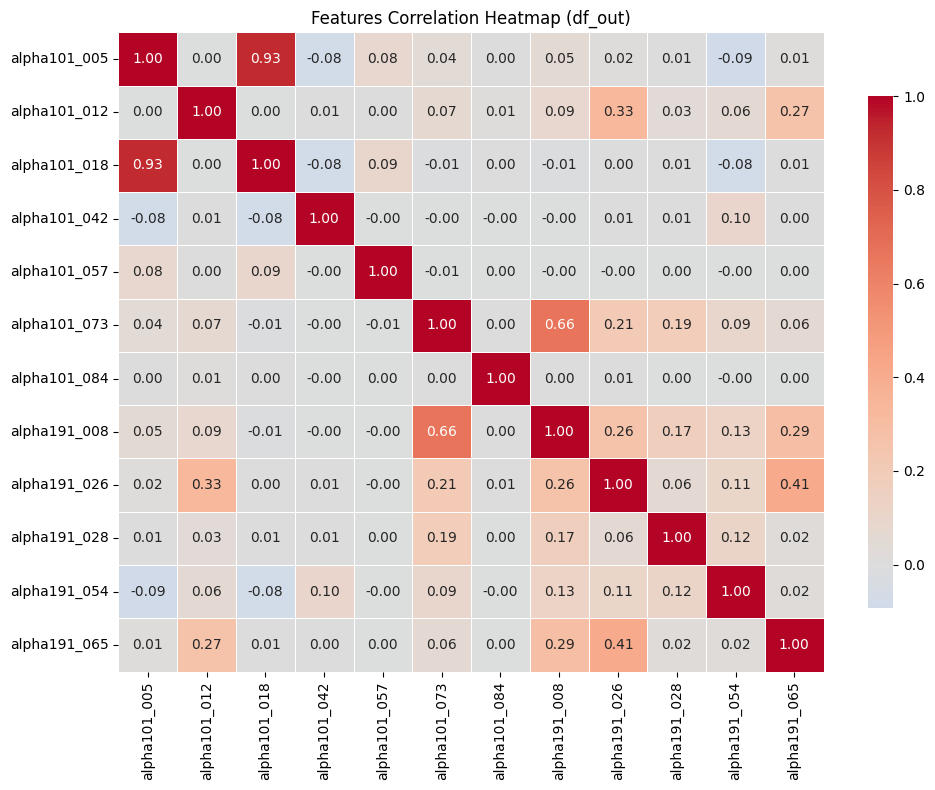

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 只對數值型特徵繪製相關性熱圖
numeric_cols = df_out.select_dtypes(include=[np.number]).columns
corr = df_out[numeric_cols].corr()

plt.figure(figsize=(len(numeric_cols) * 0.6 + 3, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Features Correlation Heatmap (df_out)")
plt.tight_layout()
plt.show()